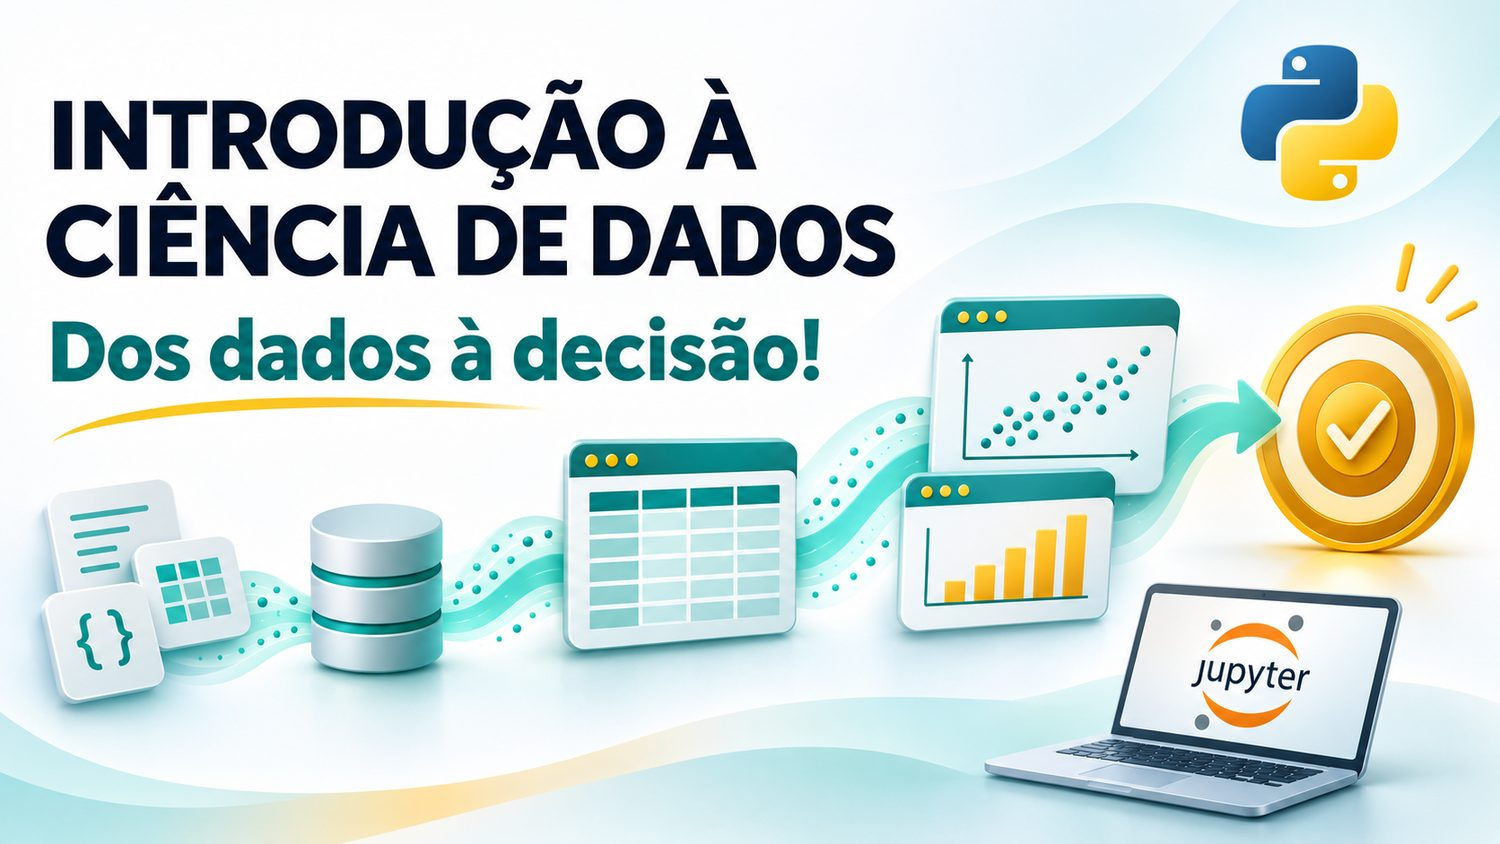

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/05_Associacao_e_Correlacoes_Espurias.ipynb)

# Capítulo 5 – Associação e correlações espúrias

Dizer que duas variáveis «estão relacionadas» é a afirmação mais frequente em análise de dados e uma das mais mal usadas. Este capítulo ensina a medir a associação, mostra o que o coeficiente de correlação não vê e explica como aparecem as correlações que não querem dizer nada.

> **Objetivos:** ler um gráfico de dispersão; calcular e interpretar a covariância e os coeficientes de Pearson e de Spearman; reconhecer relações que a correlação não deteta; ler uma matriz de correlações; identificar correlações espúrias causadas por uma tendência comum, por uma terceira variável ou por muitas comparações.

**Pré-requisitos:** capítulos 1 a 4 deste módulo, e o capítulo 2 do módulo 1 (associação e causalidade).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_escolas(semente=11):
    """Gera o consumo diário de eletricidade de 30 escolas fictícias durante um ano letivo (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    n = 30
    tipo = rng.choice(["básica", "secundária"], n, p=[0.6, 0.4])
    alunos = np.where(tipo == "básica", rng.integers(120, 520, n), rng.integers(450, 1400, n))
    escolas = pd.DataFrame({
        "escola_id": [f"E{i:02d}" for i in range(1, n + 1)],
        "tipo": tipo,
        "alunos": alunos,
        "area_m2": (alunos * rng.normal(9.0, 1.2, n)).round(-1).astype(int),
        "ano_construcao": rng.integers(1965, 2016, n),
        "paineis_solares": rng.random(n) < 0.3})
    dias = pd.date_range("2025-09-01", "2026-08-31", freq="D")
    dia_do_ano = dias.dayofyear.to_numpy()
    temperatura = 16.5 + 7.5 * np.cos(2 * np.pi * (dia_do_ano - 205) / 365) + rng.normal(0, 2.2, len(dias))
    ferias = (((dias >= "2025-12-20") & (dias <= "2026-01-04")) | ((dias >= "2026-03-28") & (dias <= "2026-04-12"))
              | (dias >= "2026-07-01"))
    meteo = pd.DataFrame({"data": dias, "temperatura": temperatura.round(1), "ferias": ferias})
    tabelas = []
    for e in escolas.itertuples():
        base = 0.55 * e.alunos + 0.012 * e.area_m2 * (1.25 if e.ano_construcao < 1990 else 1.0)
        aquecimento = 1 + 0.045 * np.clip(15 - temperatura, 0, None)
        ocupacao = np.where(dias.dayofweek >= 5, 0.22, 1.0) * np.where(ferias, 0.30, 1.0)
        sol = np.clip(0.5 + 0.5 * np.cos(2 * np.pi * (dia_do_ano - 172) / 365), 0, 1)
        solar = 1 - (0.28 * sol if e.paineis_solares else 0)
        kwh = base * aquecimento * np.maximum(ocupacao, 0.08) * solar * rng.lognormal(0, 0.10, len(dias))
        avarias = rng.random(len(dias)) < 0.004                     # dias com um consumo anormal
        kwh = np.where(avarias, kwh * rng.uniform(2.5, 4.0, len(dias)), kwh)
        tabelas.append(pd.DataFrame({"escola_id": e.escola_id, "data": dias, "kwh": kwh.round(1)}))
    return escolas, pd.concat(tabelas, ignore_index=True), meteo


escolas, consumo, meteo = gerar_escolas()
consumo.head()

,escola_id,data,kwh
0,E01,2025-09-01,300.5
1,E01,2025-09-02,264.6
2,E01,2025-09-03,265.0
3,E01,2025-09-04,270.0
4,E01,2025-09-05,303.9


In [3]:
anual = consumo.groupby("escola_id")["kwh"].sum().rename("kwh_ano").reset_index().merge(escolas, on="escola_id")
anual["mwh_ano"] = anual["kwh_ano"] / 1000
anual.head(3)

,escola_id,kwh_ano,tipo,alunos,area_m2,ano_construcao,paineis_solares,mwh_ano
0,E01,76749.1,básica,431,3750,1973,False,76.7491
1,E02,45872.9,básica,306,3040,2008,True,45.8729
2,E03,203103.9,secundária,1158,9810,1980,False,203.1039


## Ver primeiro, medir depois

A associação entre duas variáveis numéricas vê-se num gráfico de dispersão: cada ponto é uma unidade (aqui, uma escola), com uma variável em cada eixo.

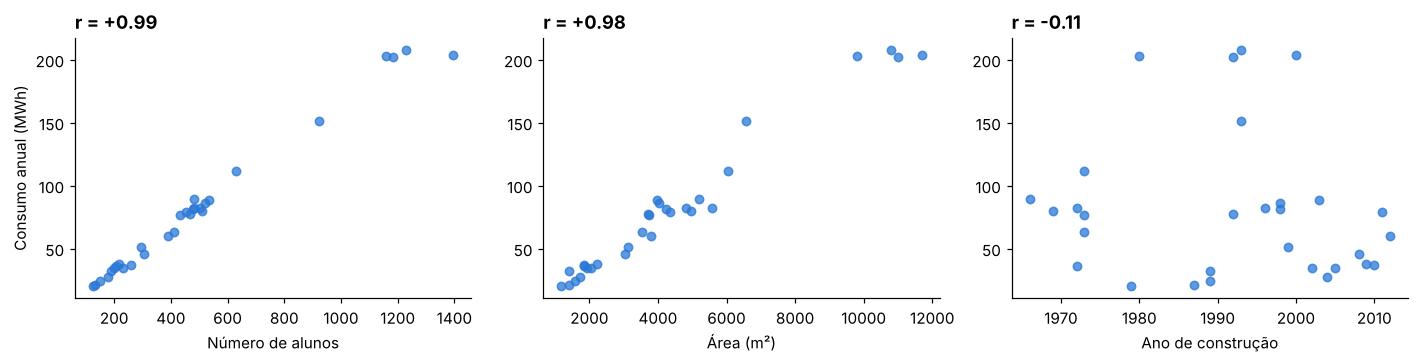

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, coluna, nome in zip(eixos, ["alunos", "area_m2", "ano_construcao"], ["Número de alunos", "Área (m²)", "Ano de construção"]):
    ax.scatter(anual[coluna], anual["mwh_ano"], s=30, color=AZUL, alpha=0.75)
    r = anual[coluna].corr(anual["mwh_ano"])
    ax.set_xlabel(nome)
    ax.set_title(f"r = {r:+.2f}")
eixos[0].set_ylabel("Consumo anual (MWh)")
plt.tight_layout()
plt.show()

Num gráfico de dispersão procuram-se quatro coisas:

- a **direção**: quando uma sobe, a outra sobe (associação positiva) ou desce (negativa)?
- a **forma**: os pontos seguem uma reta, uma curva, ou nada?
- a **força**: estão apertados em torno da forma, ou dispersos?
- as **exceções**: há pontos longe de todos os outros?

As duas primeiras nuvens são retas apertadas a subir. A terceira não tem forma nenhuma.

## Covariância e correlação

A **covariância** mede se duas variáveis se desviam das suas médias no mesmo sentido. Para cada escola multiplica-se o desvio numa variável pelo desvio na outra, e faz-se a média.

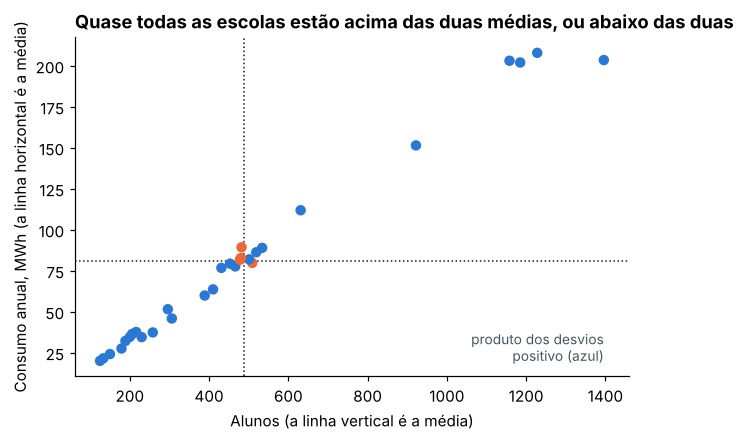

Covariância: 19862 alunos × MWh
Com a área em vez dos alunos: 167411 m² × MWh


In [5]:
x, y = anual["alunos"], anual["mwh_ano"]
dx, dy = x - x.mean(), y - y.mean()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(x, y, s=34, color=np.where(dx * dy > 0, AZUL, LARANJA), zorder=3)
ax.axvline(x.mean(), color=TINTA, ls=":", lw=1)
ax.axhline(y.mean(), color=TINTA, ls=":", lw=1)
ax.text(x.max(), y.min(), "produto dos desvios\npositivo (azul)", ha="right", fontsize=9, color="#465463")
ax.set_xlabel("Alunos (a linha vertical é a média)")
ax.set_ylabel("Consumo anual, MWh (a linha horizontal é a média)")
ax.set_title("Quase todas as escolas estão acima das duas médias, ou abaixo das duas")
plt.show()

covariancia = (dx * dy).sum() / (len(x) - 1)
print(f"Covariância: {covariancia:.0f} alunos × MWh")
print(f"Com a área em vez dos alunos: {anual['area_m2'].cov(anual['mwh_ano']):.0f} m² × MWh")

A covariância tem um defeito: depende das unidades. A da área é mais de oito vezes maior do que a dos alunos, só porque as áreas são números maiores. Não se podem comparar.

O **coeficiente de correlação de Pearson** (*r*) resolve isso dividindo a covariância pelos dois desvios padrão. O resultado não tem unidade e fica sempre entre −1 e +1.

| Valor de r | Leitura |
| --- | --- |
| +1 | Os pontos estão exatamente sobre uma reta a subir |
| perto de +1 | Associação linear positiva forte |
| perto de 0 | Não há associação **linear** |
| perto de −1 | Associação linear negativa forte |
| −1 | Os pontos estão exatamente sobre uma reta a descer |

In [6]:
r = covariancia / (x.std() * y.std())
print(f"À mão: r = {r:.3f}   |   com o pandas: r = {x.corr(y):.3f}")

À mão: r = 0.993   |   com o pandas: r = 0.993


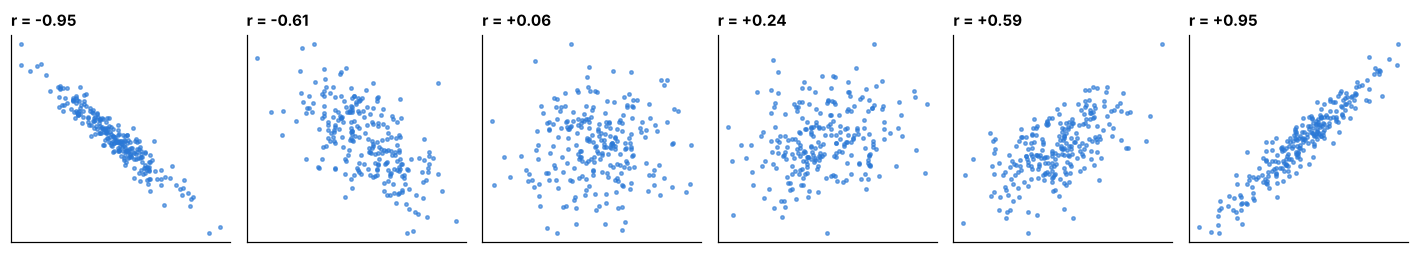

In [7]:
rng = np.random.default_rng(1)
fig, eixos = plt.subplots(1, 6, figsize=(13, 2.4))
for ax, alvo in zip(eixos, [-0.95, -0.6, 0.0, 0.3, 0.6, 0.95]):
    a = rng.normal(size=250)
    b = alvo * a + np.sqrt(1 - alvo ** 2) * rng.normal(size=250)
    ax.scatter(a, b, s=5, color=AZUL, alpha=0.6)
    ax.set_title(f"r = {np.corrcoef(a, b)[0, 1]:+.2f}", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Vale a pena fixar o aspeto destas seis nuvens. Uma correlação de 0,3, que em muitos relatórios aparece como «relação positiva», é quase indistinguível de uma nuvem sem forma.

## O que a correlação não vê

### Relações que não são retas

O coeficiente de Pearson mede a proximidade a uma **reta**. Uma relação forte com outra forma pode ter uma correlação próxima de zero.

Já vimos um caso: o consumo sobe com o frio abaixo de 15 °C e é plano acima disso. Vamos acrescentar-lhe um aparelho de ar condicionado imaginário, que faz subir o consumo também com o calor.

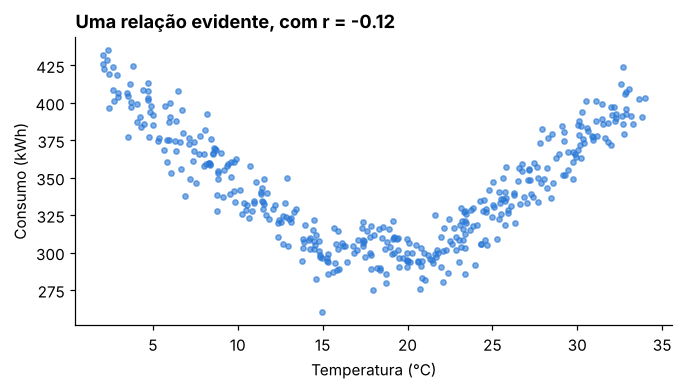

In [8]:
rng = np.random.default_rng(3)
temperatura = rng.uniform(2, 34, 400)
com_ar_condicionado = 300 + 9 * np.clip(15 - temperatura, 0, None) + 9 * np.clip(temperatura - 22, 0, None) + rng.normal(0, 12, 400)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(temperatura, com_ar_condicionado, s=12, color=AZUL, alpha=0.6)
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Consumo (kWh)")
ax.set_title(f"Uma relação evidente, com r = {np.corrcoef(temperatura, com_ar_condicionado)[0, 1]:+.2f}")
plt.show()

O consumo depende quase totalmente da temperatura, e a correlação é praticamente nula: o lado que sobe anula o lado que desce.

> **r perto de zero quer dizer «sem relação linear», e não «sem relação».**

### Valores extremos e relações monótonas

O coeficiente de Pearson usa os valores, e por isso um ponto extremo pode criá-lo ou destruí-lo. O **coeficiente de Spearman** usa as **posições** (o 1.º, o 2.º, o 3.º…) em vez dos valores. Mede se uma variável cresce quando a outra cresce, sem exigir que seja em linha reta, e é robusto a valores extremos.

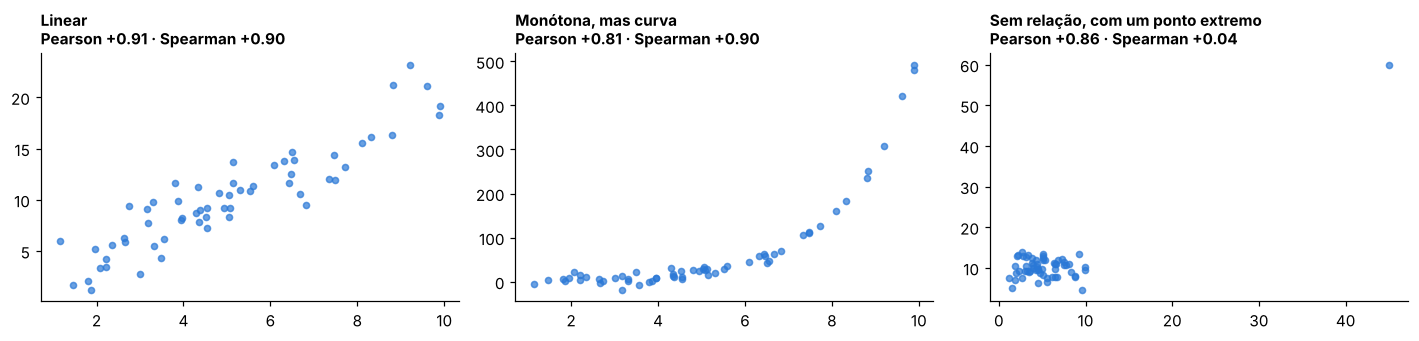

In [9]:
rng = np.random.default_rng(8)
a = rng.uniform(1, 10, 60)
exemplos = [("Linear", a, 2 * a + rng.normal(0, 2, 60)),
            ("Monótona, mas curva", a, np.exp(a / 1.6) + rng.normal(0, 8, 60)),
            ("Sem relação, com um ponto extremo", np.append(a[:-1], 45), np.append(rng.normal(10, 2, 59), 60))]

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (titulo, u, v) in zip(eixos, exemplos):
    u, v = pd.Series(u), pd.Series(v)
    ax.scatter(u, v, s=16, color=AZUL, alpha=0.7)
    ax.set_title(f"{titulo}\nPearson {u.corr(v):+.2f} · Spearman {u.corr(v, method='spearman'):+.2f}", fontsize=10)
plt.tight_layout()
plt.show()

- Na relação linear, os dois coeficientes concordam.
- Na relação curva, Spearman fica perto de 1 (a ordem é quase perfeita) e Pearson fica mais baixo (não é uma reta).
- No terceiro caso, um único ponto dá a Pearson um valor alto. Spearman, que só vê esse ponto como «o maior», fica perto de zero.

Quando os dois coeficientes são muito diferentes, há uma curva ou um ponto extremo. Em qualquer dos casos, a resposta está no gráfico.

## A matriz de correlações

Com várias variáveis, calculam-se todas as correlações de uma vez.

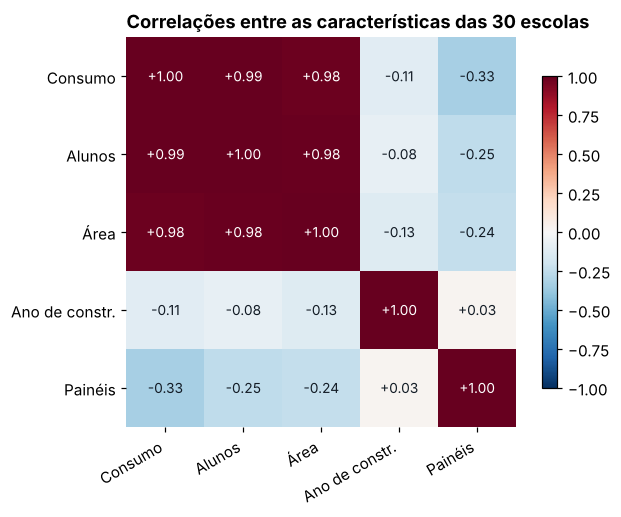

In [10]:
variaveis = anual[["mwh_ano", "alunos", "area_m2", "ano_construcao", "paineis_solares"]].astype(float)
variaveis.columns = ["Consumo", "Alunos", "Área", "Ano de constr.", "Painéis"]
matriz = variaveis.corr()

fig, ax = plt.subplots(figsize=(6, 4.6))
imagem = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5), matriz.columns, rotation=30, ha="right")
ax.set_yticks(range(5), matriz.index)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matriz.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(matriz.iloc[i, j]) > 0.6 else TINTA)
fig.colorbar(imagem, ax=ax, shrink=0.8)
ax.spines[:].set_visible(False)
ax.set_title("Correlações entre as características das 30 escolas")
plt.show()

Como ler:

- A diagonal é sempre 1 (cada variável consigo própria), e a matriz é simétrica.
- O consumo está fortemente associado ao número de alunos **e** à área. Mas os alunos e a área também estão fortemente associados entre si: as duas medem quase a mesma coisa, o tamanho da escola. Não são duas explicações independentes.
- Os painéis solares têm uma correlação fraca com o consumo total. Isso não quer dizer que não funcionem: o efeito do tamanho é tão grande que esconde tudo o resto.

A matriz é um bom primeiro olhar e um mau último. Só vê relações lineares, duas variáveis de cada vez.

## Correlações espúrias

Uma correlação é **espúria** quando existe nos dados sem que haja uma ligação real entre as variáveis. Há três mecanismos principais.

### 1. Uma terceira variável por trás

As escolas com mais computadores gastam mais eletricidade. Devem trocar-se os computadores?

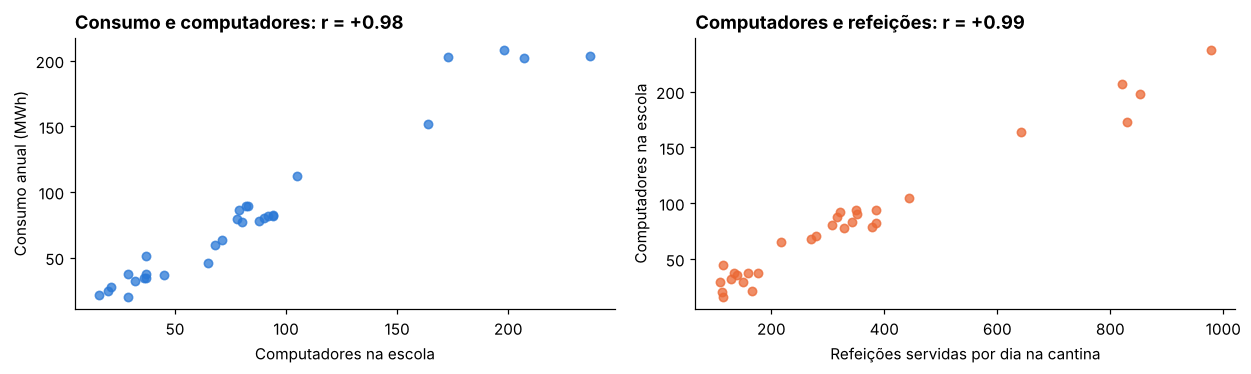

In [11]:
rng = np.random.default_rng(6)
anual["computadores"] = (anual["alunos"] / 6 + rng.normal(0, 8, len(anual))).round().clip(lower=5)
anual["refeicoes_dia"] = (anual["alunos"] * 0.7 + rng.normal(0, 20, len(anual))).round()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax1.scatter(anual["computadores"], anual["mwh_ano"], s=30, color=AZUL, alpha=0.75)
ax1.set_xlabel("Computadores na escola")
ax1.set_ylabel("Consumo anual (MWh)")
ax1.set_title(f"Consumo e computadores: r = {anual['computadores'].corr(anual['mwh_ano']):+.2f}")
ax2.scatter(anual["refeicoes_dia"], anual["computadores"], s=30, color=LARANJA, alpha=0.75)
ax2.set_xlabel("Refeições servidas por dia na cantina")
ax2.set_ylabel("Computadores na escola")
ax2.set_title(f"Computadores e refeições: r = {anual['refeicoes_dia'].corr(anual['computadores']):+.2f}")
plt.tight_layout()
plt.show()

Os computadores estão fortemente associados ao consumo, e também ao número de refeições servidas na cantina, com as quais não têm ligação nenhuma. As três variáveis dependem de uma quarta: **o número de alunos**. É a variável de confusão do módulo 1.

Para tirar o efeito do tamanho, comparam-se taxas.

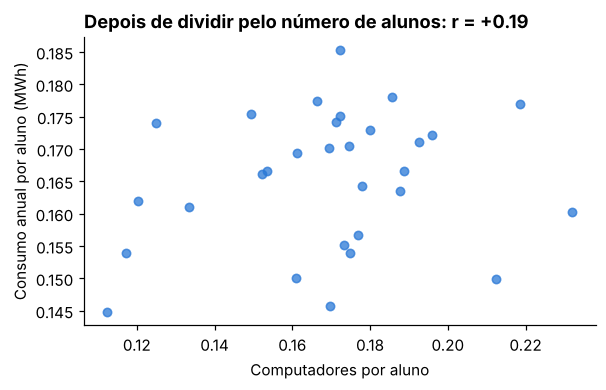

In [12]:
anual["mwh_por_aluno"] = anual["mwh_ano"] / anual["alunos"]
anual["computadores_por_aluno"] = anual["computadores"] / anual["alunos"]

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(anual["computadores_por_aluno"], anual["mwh_por_aluno"], s=30, color=AZUL, alpha=0.75)
ax.set_xlabel("Computadores por aluno")
ax.set_ylabel("Consumo anual por aluno (MWh)")
ax.set_title(f"Depois de dividir pelo número de alunos: r = {anual['computadores_por_aluno'].corr(anual['mwh_por_aluno']):+.2f}")
plt.show()

Dividindo as duas variáveis pelo número de alunos, a associação quase desaparece. Nestes dados sintéticos os computadores foram gerados sem qualquer efeito no consumo, e a correlação inicial era toda devida ao tamanho.

### 2. Uma tendência comum

Duas séries que crescem ao longo do tempo ficam correlacionadas, mesmo que não tenham nada a ver uma com a outra.

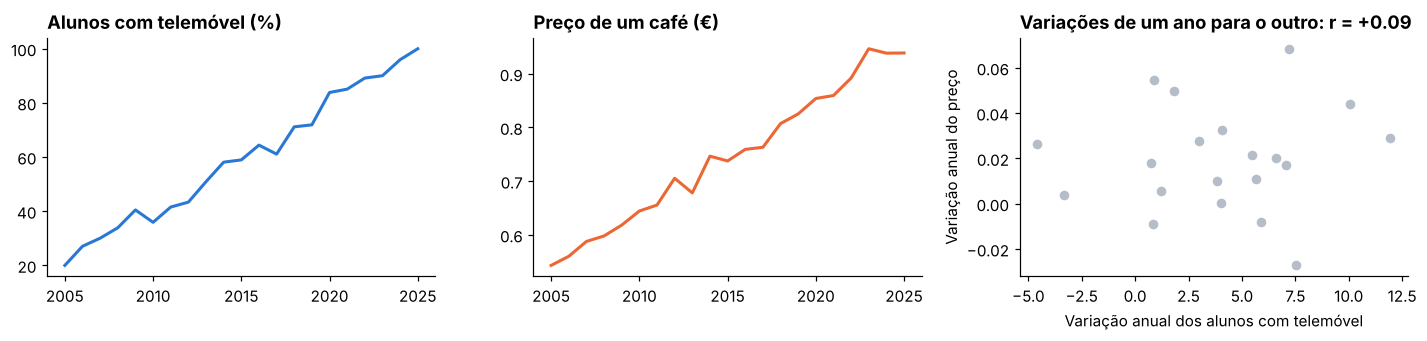

Correlação entre as duas séries: r = +0.99


In [13]:
rng = np.random.default_rng(12)
anos = np.arange(2005, 2026)
alunos_com_telemovel = np.clip(20 + 3.9 * (anos - 2005) + rng.normal(0, 3, len(anos)), 0, 100)      # % de alunos
preco_do_cafe = 0.55 + 0.02 * (anos - 2005) + rng.normal(0, 0.02, len(anos))                         # euros

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.2))
ax1.plot(anos, alunos_com_telemovel, color=AZUL, lw=2)
ax1.set_title("Alunos com telemóvel (%)")
ax2.plot(anos, preco_do_cafe, color=LARANJA, lw=2)
ax2.set_title("Preço de um café (€)")
ax3.scatter(np.diff(alunos_com_telemovel), np.diff(preco_do_cafe), s=28, color=CINZA)
ax3.set_xlabel("Variação anual dos alunos com telemóvel")
ax3.set_ylabel("Variação anual do preço")
ax3.set_title(f"Variações de um ano para o outro: r = {np.corrcoef(np.diff(alunos_com_telemovel), np.diff(preco_do_cafe))[0, 1]:+.2f}")
plt.tight_layout()
plt.show()

print(f"Correlação entre as duas séries: r = {np.corrcoef(alunos_com_telemovel, preco_do_cafe)[0, 1]:+.2f}")

As duas séries inventadas têm uma correlação próxima de 1, e ninguém defenderia que os telemóveis encarecem o café. O que partilham é o **tempo**: ambas sobem ano após ano.

A defesa é correlacionar as **variações** em vez dos níveis (o terceiro gráfico). Se uma série influencia a outra, os anos em que uma sobe mais devem ser os anos em que a outra também sobe mais. Aqui não são.

### 3. Procurar até encontrar

Com muitas variáveis, algumas ficam correlacionadas por puro acaso (módulo 1, capítulo 5). O efeito é pior em amostras pequenas.

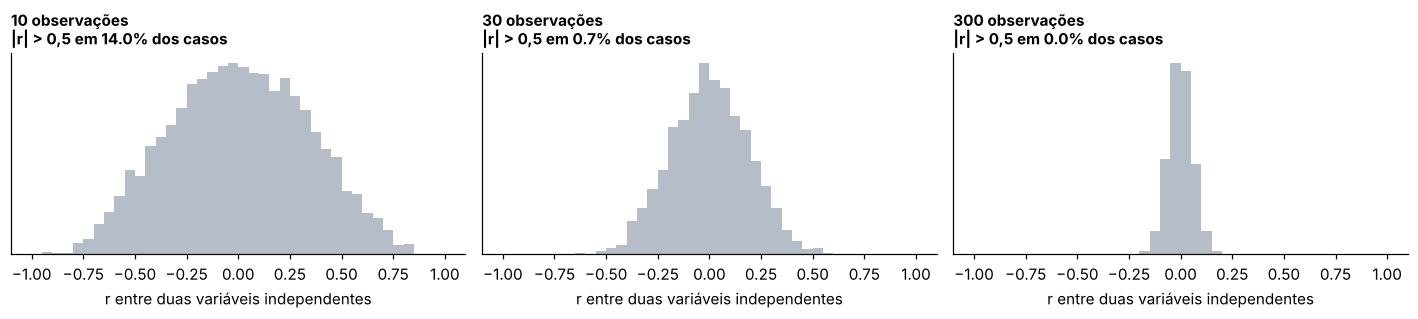

In [14]:
rng = np.random.default_rng(21)
fig, eixos = plt.subplots(1, 3, figsize=(13, 3))
for ax, n in zip(eixos, [10, 30, 300]):
    correlacoes = [np.corrcoef(rng.normal(size=n), rng.normal(size=n))[0, 1] for _ in range(4000)]
    ax.hist(correlacoes, bins=np.linspace(-1, 1, 41), color=CINZA)
    fortes = np.mean(np.abs(correlacoes) > 0.5) * 100
    ax.set_title(f"{n} observações\n|r| > 0,5 em {fortes:.1f}% dos casos", fontsize=10)
    ax.set_xlabel("r entre duas variáveis independentes")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Com 10 observações, duas variáveis sem qualquer relação dão uma correlação «forte» (acima de 0,5 em valor absoluto) em mais de um caso em dez. Com 300, isso praticamente nunca acontece. As nossas 30 escolas estão no meio: uma correlação de 0,3 entre duas características não quer dizer nada.

## Antes de acreditar numa correlação

1. **Olhei para o gráfico?** A forma é uma reta? Há pontos extremos?
2. **Quantas observações tenho?** Com poucas, o acaso produz correlações fortes.
3. **Quantas correlações calculei?** Se procurei em cinquenta, encontrei algumas por acaso.
4. **Há uma terceira variável** que possa explicar as duas? O tamanho e o tempo são as mais comuns.
5. **As duas variáveis têm tendência?** Se sim, correlaciona as variações.
6. **A direção é a que eu penso?** Pode ser a inversa.

Uma correlação é um bom motivo para fazer uma pergunta. Só por si, não é uma resposta.

## Exercícios

### `Exercício 1` – Estimar à vista

Para cada par, diz se esperas uma correlação positiva, negativa ou próxima de zero, e se será forte ou fraca:

1. A altura e o número do calçado de adultos.
2. A temperatura exterior e o consumo de aquecimento.
3. O número de porta e o rendimento do agregado.
4. As horas de estudo e a nota num exame.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Positiva e forte.
2. Negativa e forte.
3. Próxima de zero.
4. Positiva, moderada: há muitos outros fatores (e pode não ser linear, porque a partir de certo ponto mais horas ajudam pouco).

</details>

### `Exercício 2` – Pearson e Spearman

Calcula os dois coeficientes entre a temperatura e o consumo diário da escola `E03` em dias de aulas. São parecidos? Depois calcula-os só para os dias abaixo de 15 °C. O que mudou, e porquê?

In [15]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = consumo.merge(meteo, on="data")
t = t[(t["escola_id"] == "E03") & (t["data"].dt.dayofweek < 5) & ~t["ferias"]]
for nome, parte in [("Todos os dias", t), ("Abaixo de 15 °C", t[t["temperatura"] < 15])]:
    print(nome, round(parte["temperatura"].corr(parte["kwh"]), 2), round(parte["temperatura"].corr(parte["kwh"], method="spearman"), 2))
```

Só com os dias frios, a correlação de Pearson fica mais forte (mais negativa): nesse intervalo a relação é uma reta. Com todos os dias, a parte plana acima de 15 °C enfraquece-a. Os dias de consumo anormal também pesam em Pearson e quase nada em Spearman.

</details>

### `Exercício 3` – Encontrar a terceira variável

Explica cada uma destas correlações, todas reais em muitos conjuntos de dados:

1. As cidades com mais bombeiros têm mais incêndios.
2. As crianças que calçam números maiores leem melhor.
3. Nos meses em que se vendem mais gelados há mais afogamentos.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. O tamanho da cidade: mais habitantes, mais bombeiros e mais incêndios. Deve comparar-se por habitante.
2. A idade: as crianças mais velhas têm os pés maiores e leem melhor.
3. A estação do ano: no verão comem-se mais gelados e vai-se mais à praia.

</details>

### `Exercício 4` – Fabricar uma correlação espúria

Cria uma tabela com 30 linhas e 40 colunas de números aleatórios. Calcula a matriz de correlações e encontra o par de colunas com a correlação mais forte. Qual é o valor? O que conclui quem não souber como a tabela foi feita?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rng = np.random.default_rng(0)
ruido = pd.DataFrame(rng.normal(size=(30, 40)))
c = ruido.corr().abs()
c = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))      # só a metade de cima, sem a diagonal
par = c.stack().idxmax()
print(par, round(ruido[par[0]].corr(ruido[par[1]]), 2), "| pares testados:", int(c.count().sum()))
```

Entre 780 pares de colunas sem qualquer relação, o mais forte tem uma correlação acima de 0,5. Apresentado sozinho, pareceria uma descoberta. É por isto que se diz sempre quantas comparações se fizeram.

</details>

## Verifica o que aprendeste

- [ ] Sei ler a direção, a forma, a força e as exceções num gráfico de dispersão.
- [ ] Sei o que mede a covariância e porque não se compara entre variáveis.
- [ ] Sei interpretar o coeficiente de Pearson e reconhecer o aspeto de uma nuvem com r = 0,3 e com r = 0,9.
- [ ] Sei dar um exemplo de uma relação forte com correlação nula.
- [ ] Sei quando usar o coeficiente de Spearman.
- [ ] Sei ler uma matriz de correlações.
- [ ] Sei explicar três mecanismos que produzem correlações espúrias.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Pearson_correlation_coefficient
- https://en.wikipedia.org/wiki/Spearman%27s_rank_correlation_coefficient
- https://en.wikipedia.org/wiki/Spurious_relationship
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html